## Policy Evaluation: TD(0), TD(λ), True Online TD(λ)

We compare three online evaluators using two feature matrices (tabular and shared linear features) on each environment. The policy is fixed during evaluation; all methods minimize costs.

The underlying stochastic TD formula follows the lecture and Q2:

\(\widetilde F_t(\theta_t)=\phi_t\left(\phi_t^\top\theta_t-c_t-\gamma\phi_{t+1}^\top\theta_t\right),\qquad \theta_{t+1}=\theta_t-\eta\widetilde F_t(\theta_t).\)

With $\delta_t=c_t+\gamma\phi_{t+1}^\top\theta_t-\phi_t^\top\theta_t$, the update is $\theta_{t+1}=\theta_t+\eta\delta_t\phi_t$.

Run the notebook using Kernel → Restart & Run All. Keep the entire policy_evaluation/ folder next to baseline.py, grid_world_env.py, and blackjack_env.py.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Run the notebook from either the project root or policy_evaluation/.
root = Path.cwd()
if not (root / "blackjack_env.py").exists():
    root = root.parent
sys.path.insert(0, str(root))

from grid_world_env import GridWorld
from blackjack_env import Blackjack
from policy_eval_td_enhanements import (
    tabular_features, linear_features,
    td_zero, td_lambda, true_online_td_lambda,
)

plt.style.use("ggplot")

ENVIRONMENTS = ["blackjack", "gridworld"]
N_STEPS = 2000            # Online training transitions per method
RECORD_EVERY = 100
ETA = 0.05
LAM = 0.8
SEED = 42
REFERENCE_ROLLOUTS = 300 # Independent validation only; not training
REFERENCE_HORIZON = 80
RUN_TOMC = False          # Optional; GridWorld coverage may fail

output = root / "policy_evaluation_results"
output.mkdir(exist_ok=True)

In [2]:
def validate_start_value(env, pi, s_0, rng):
    returns = []
    for _ in range(REFERENCE_ROLLOUTS):
        s = s_0
        total = 0.0
        discount = 1.0
        for _ in range(REFERENCE_HORIZON):
            a = int(rng.choice(env.n_actions, p=pi[s]))
            next_s, cost, done = env.step_one(s, a, rng)
            total += discount * cost
            if done:
                break
            discount *= env.gamma
            s = next_s
        returns.append(total)
    return float(np.mean(returns))

## Run the six TD configurations
For conventional TD(λ), we use $e_t=\gamma\lambda e_{t-1}+\phi_t$ and $\theta_{t+1}=\theta_t+\eta\delta_te_t$.

True Online TD(λ) uses the Dutch trace

\(e_t=\gamma\lambda e_{t-1}+(1-\eta\gamma\lambda e_{t-1}^\top\phi_t)\phi_t\)

and the correction term shown in the proposal. The traces reset at Blackjack termination; GridWorld is continuing. All methods use the same random seed and observation budget for easy comparison.

In [3]:
all_results = {}

for name in ENVIRONMENTS:
    env = Blackjack() if name == "blackjack" else GridWorld()
    s_0 = env.encode(8, 3) if name == "blackjack" else env.start
    pi = np.full((env.n_states, env.n_actions), 1 / env.n_actions)
    reference_v = validate_start_value(env, pi, s_0,
                                       np.random.default_rng(SEED + 100))

    records = []
    for feature_name, feature_fn in [
        ("Tabular", tabular_features),
        ("Linear", linear_features),
    ]:
        Phi = feature_fn(env)
        for method_name, td_fn in [
            ("TD(0)", td_zero),
            ("TD(lambda)", td_lambda),
            ("True Online TD(lambda)", true_online_td_lambda),
        ]:
            kwargs = dict(env=env, pi=pi, Phi=Phi, n_steps=N_STEPS,
                          eta=ETA, rng=np.random.default_rng(SEED),
                          record_every=RECORD_EVERY)
            if td_fn != td_zero:
                kwargs["lam"] = LAM
            Q, n_samples, history = td_fn(**kwargs)

            for observations, Q_t in history:
                estimated_v = float(pi[s_0] @ Q_t[s_0])
                records.append(dict(method=method_name, features=feature_name,
                                    observations=observations, estimated_v=estimated_v,
                                    absolute_value_difference=abs(estimated_v - reference_v)))
            print(f"{name:10} | {feature_name:7} | {method_name:23} | "
                  f"parameters={Phi.shape[1]:3} | observations={n_samples}")

    results = pd.DataFrame(records)
    all_results[name] = dict(results=results, reference_v=reference_v)
    results.to_csv(output / f"{name}_td_history.csv", index=False)
    print(f"{name} sampled reference V(s_0): {reference_v:.4f}\n")

blackjack  | Tabular | TD(0)                   | parameters= 64 | observations=2000
blackjack  | Tabular | TD(lambda)              | parameters= 64 | observations=2000
blackjack  | Tabular | True Online TD(lambda)  | parameters= 64 | observations=2000
blackjack  | Linear  | TD(0)                   | parameters= 16 | observations=2000
blackjack  | Linear  | TD(lambda)              | parameters= 16 | observations=2000
blackjack  | Linear  | True Online TD(lambda)  | parameters= 16 | observations=2000
blackjack sampled reference V(s_0): 0.6057

gridworld  | Tabular | TD(0)                   | parameters=400 | observations=2000
gridworld  | Tabular | TD(lambda)              | parameters=400 | observations=2000
gridworld  | Tabular | True Online TD(lambda)  | parameters=400 | observations=2000
gridworld  | Linear  | TD(0)                   | parameters=100 | observations=2000
gridworld  | Linear  | TD(lambda)              | parameters=100 | observations=2000
gridworld  | Linear  | True Onli

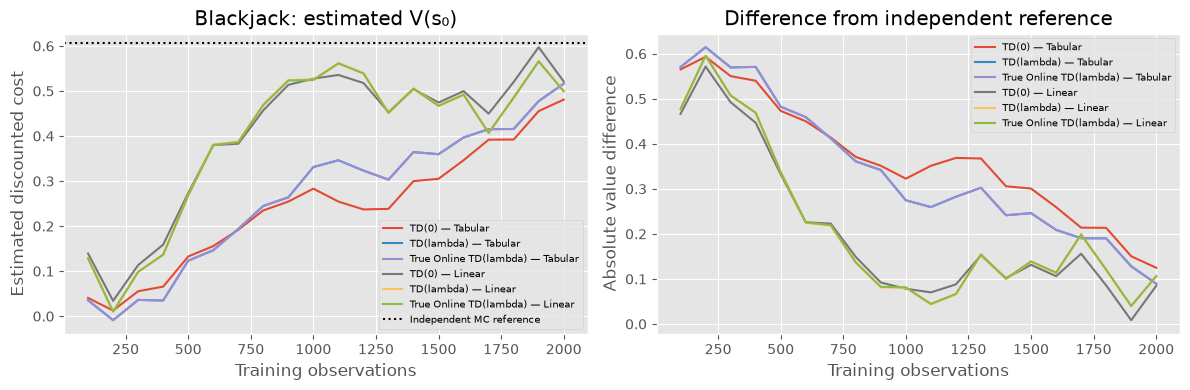

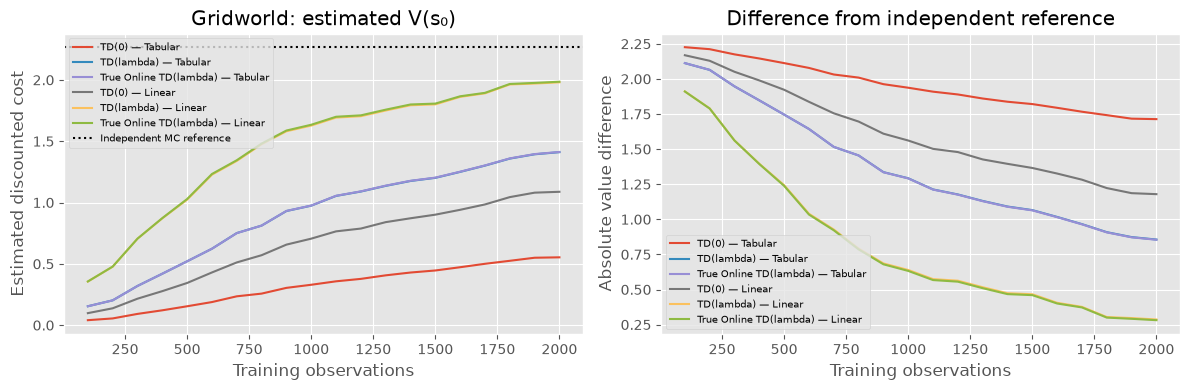

In [4]:
for name, result in all_results.items():
    data = result["results"]
    reference_v = result["reference_v"]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for (features, method), group in data.groupby(["features", "method"], sort=False):
        label = f"{method} — {features}"
        axes[0].plot(group.observations, group.estimated_v, label=label)
        axes[1].plot(group.observations, group.absolute_value_difference, label=label)

    axes[0].axhline(reference_v, color="black", linestyle="dotted",
                    label="Independent MC reference")
    axes[0].set(xlabel="Training observations", ylabel="Estimated discounted cost",
                title=f"{name.title()}: estimated V(s₀)")
    axes[1].set(xlabel="Training observations", ylabel="Absolute value difference",
                title="Difference from independent reference")
    axes[0].legend(fontsize=7)
    axes[1].legend(fontsize=7)
    fig.tight_layout()
    fig.savefig(output / f"{name}_td_comparison.png", dpi=160)
    plt.show()

In [5]:
if RUN_TOMC:
    from baseline import tomc
    for name in ENVIRONMENTS:
        env = Blackjack() if name == "blackjack" else GridWorld()
        pi = np.full((env.n_states, env.n_actions), 1 / env.n_actions)
        s_0 = env.encode(8, 3) if name == "blackjack" else env.start
        try:
            Q, n = tomc(env, pi, np.random.default_rng(SEED),
                        bias=0.01, max_observations=200_000)
            print(name, "TOMC observations:", n,
                  "estimated V(s0):", float(pi[s_0] @ Q[s_0]))
        except RuntimeError as error:
            print(name, error)